# Statistical matching

Run the configured matching methods on the regression-owned input, show relative and absolute outcome estimates, and display the covariate-balance plot.

Statistical matching reads the same file from `[regression.outputs].directory / author_regression_input.csv`; in this config, that is `data/output/synthetic/regression/author_regression_input.csv`. It reuses the file when present. If it is absent, the stage attempts to run the configured regression-input producer; that attempt requires the configured external inputs and upstream mobility artifact, and can fail if they are unavailable. No separate matching input path is configured.

In [1]:
from pathlib import Path
import sys

from IPython.display import Image, display

repo_root = Path.cwd()
while not (repo_root / 'pyproject.toml').is_file() and repo_root != repo_root.parent:
    repo_root = repo_root.parent
if not (repo_root / 'pyproject.toml').is_file():
    raise RuntimeError('Start Jupyter from within the academic-inbreeding repository.')
sys.path.insert(0, str(repo_root / 'src'))

from acib.pipeline.config import load_statistical_matching_config
from acib.statistical_matching.constants import COVARIATE_BALANCE_FIGURE_FILENAME
from acib.statistical_matching.workflow import run_statistical_matching_suite_from_config

## 1. Load the shared synthetic configuration

The matching options and output directory come from `pipeline_synthetic.toml`. Statistical matching consumes the regression stage's configured `author_regression_input.csv`; it does not declare a second input path.

In [2]:
config_path = repo_root / 'config' / 'pipeline_synthetic.toml'
config = load_statistical_matching_config(config_path)
print(f'Config: {config_path.relative_to(repo_root)}')
print(f'Regression input: {config.input_path.relative_to(repo_root)}')
print(f'Methods: {config.methods}')
print(f'Output directory: {config.outputs.directory.relative_to(repo_root)}')

Config: config/pipeline_synthetic.toml
Regression input: data/output/synthetic/regression/author_regression_input.csv
Methods: ('PSM', 'IPTW', 'CEM', 'EB')
Output directory: data/output/synthetic/statistical_matching


## 2. Fit the configured statistical-matching analyses

The configured methods estimate effects for all selected relative and absolute outcomes. The stage checks that the regression-owned input exists, fits the suite, and writes its configured tables and plots.

In [3]:
result = run_statistical_matching_suite_from_config(config_path=config_path)
relative_outcomes = tuple(
    outcome for outcome in config.outcomes if config.outcome_types[outcome] == 'relative'
)
absolute_outcomes = tuple(
    outcome for outcome in config.outcomes if config.outcome_types[outcome] == 'absolute'
)
print(f'Fitted methods: {config.methods}')
print(f'Relative outcomes: {relative_outcomes}')
print(f'Absolute outcomes: {absolute_outcomes}')

Fitted methods: ('PSM', 'IPTW', 'CEM', 'EB')
Relative outcomes: ('hazen_perc_med', 'pp_top_10', 'pp_top_5', 'pp_top_1')
Absolute outcomes: ('n_public', 'P_top10', 'P_top5', 'P_top1')


## 3. Relative-outcome estimates

In [4]:
relative_effects = result.outcome_effects.loc[
    result.outcome_effects['outcome'].isin(relative_outcomes)
].copy()
display(relative_effects)

,method,outcome,n,estimate,std_error,p_value,conf_low,conf_high,ci_lower,ci_upper,estimate_display,std_error_display,conf_low_display,conf_high_display,ci_lower_display,ci_upper_display,stars,estimand
0,PSM,hazen_perc_med,7540,-5.480573,0.322733,1.681812e-63,-6.113220,-4.847927,-6.113220,-4.847927,-5.480573,0.322733,-6.113220,-4.847927,-6.113220,-4.847927,***,ATT
1,PSM,pp_top_10,7540,-0.039777,0.002933,2.021636e-41,-0.045526,-0.034028,-0.045526,-0.034028,-3.977693,0.293271,-4.552586,-3.402799,-4.552586,-3.402799,***,ATT
2,PSM,pp_top_5,7540,-0.023165,0.002008,1.572008e-30,-0.027101,-0.019228,-0.027101,-0.019228,-2.316492,0.200811,-2.710138,-1.922846,-2.710138,-1.922846,***,ATT
3,PSM,pp_top_1,7540,-0.006779,0.000672,8.868945e-24,-0.008096,-0.005462,-0.008096,-0.005462,-0.677909,0.067202,-0.809644,-0.546174,-0.809644,-0.546174,***,ATT
8,IPTW,hazen_perc_med,7807,-4.054534,0.445387,1.094906e-19,-4.927611,-3.181457,-4.927611,-3.181457,-4.054534,0.445387,-4.927611,-3.181457,-4.927611,-3.181457,***,ATT
9,IPTW,pp_top_10,7807,-0.027223,0.003703,2.147762e-13,-0.034482,-0.019965,-0.034482,-0.019965,-2.722334,0.370276,-3.448174,-1.996494,-3.448174,-1.996494,***,ATT
10,IPTW,pp_top_5,7807,-0.014295,0.002352,1.280163e-09,-0.018906,-0.009684,-0.018906,-0.009684,-1.429534,0.235228,-1.890644,-0.968424,-1.890644,-0.968424,***,ATT
11,IPTW,pp_top_1,7807,-0.004113,0.000740,2.765673e-08,-0.005563,-0.002663,-0.005563,-0.002663,-0.411305,0.073958,-0.556282,-0.266328,-0.556282,-0.266328,***,ATT
16,CEM,hazen_perc_med,5525,-2.753501,0.552383,6.393098e-07,-3.836389,-1.670612,-3.836389,-1.670612,-2.753501,0.552383,-3.836389,-1.670612,-3.836389,-1.670612,***,ATT
17,CEM,pp_top_10,5525,-0.020200,0.005139,8.572948e-05,-0.030274,-0.010125,-0.030274,-0.010125,-2.019997,0.513901,-3.027444,-1.012549,-3.027444,-1.012549,***,ATT


## 4. Absolute-outcome estimates

In [5]:
absolute_effects = result.outcome_effects.loc[
    result.outcome_effects['outcome'].isin(absolute_outcomes)
].copy()
display(absolute_effects)

,method,outcome,n,estimate,std_error,p_value,conf_low,conf_high,ci_lower,ci_upper,estimate_display,std_error_display,conf_low_display,conf_high_display,ci_lower_display,ci_upper_display,stars,estimand
4,PSM,n_public,7540,-27.247480,2.665386,2.261623e-24,-32.472380,-22.022581,-32.472380,-22.022581,-27.247480,2.665386,-32.472380,-22.022581,-32.472380,-22.022581,***,ATT
5,PSM,P_top10,7540,-5.338691,0.518128,9.876790e-25,-6.354366,-4.323016,-6.354366,-4.323016,-5.338691,0.518128,-6.354366,-4.323016,-6.354366,-4.323016,***,ATT
6,PSM,P_top5,7540,-2.992061,0.313754,1.954421e-21,-3.607107,-2.377015,-3.607107,-2.377015,-2.992061,0.313754,-3.607107,-2.377015,-3.607107,-2.377015,***,ATT
7,PSM,P_top1,7540,-0.734821,0.096558,3.070693e-14,-0.924102,-0.545539,-0.924102,-0.545539,-0.734821,0.096558,-0.924102,-0.545539,-0.924102,-0.545539,***,ATT
12,IPTW,n_public,7807,-4.940474,2.244510,2.775550e-02,-9.340315,-0.540633,-9.340315,-0.540633,-4.940474,2.244510,-9.340315,-0.540633,-9.340315,-0.540633,*,ATT
13,IPTW,P_top10,7807,-1.460646,0.423857,5.717797e-04,-2.291520,-0.629772,-2.291520,-0.629772,-1.460646,0.423857,-2.291520,-0.629772,-2.291520,-0.629772,***,ATT
14,IPTW,P_top5,7807,-0.798200,0.250488,1.445307e-03,-1.289224,-0.307177,-1.289224,-0.307177,-0.798200,0.250488,-1.289224,-0.307177,-1.289224,-0.307177,**,ATT
15,IPTW,P_top1,7807,-0.190333,0.076719,1.312538e-02,-0.340722,-0.039944,-0.340722,-0.039944,-0.190333,0.076719,-0.340722,-0.039944,-0.340722,-0.039944,*,ATT
20,CEM,n_public,5525,-4.552584,3.634607,2.104169e-01,-11.677845,2.572677,-11.677845,2.572677,-4.552584,3.634607,-11.677845,2.572677,-11.677845,2.572677,,ATT
21,CEM,P_top10,5525,-1.347310,0.647782,3.758233e-02,-2.617217,-0.077403,-2.617217,-0.077403,-1.347310,0.647782,-2.617217,-0.077403,-2.617217,-0.077403,*,ATT


Inbred professors had lower relative citation-impact outcomes in all four methods, with statistically significant estimates throughout. Absolute publication-output estimates were also generally negative, but significance varied: all four outcomes were significant with PSM and IPTW, while some were not with CEM and EB. These are adjusted associations, not causal effects.

## 5. Covariate balance

Display the configured matching workflow's covariate-balance figure.

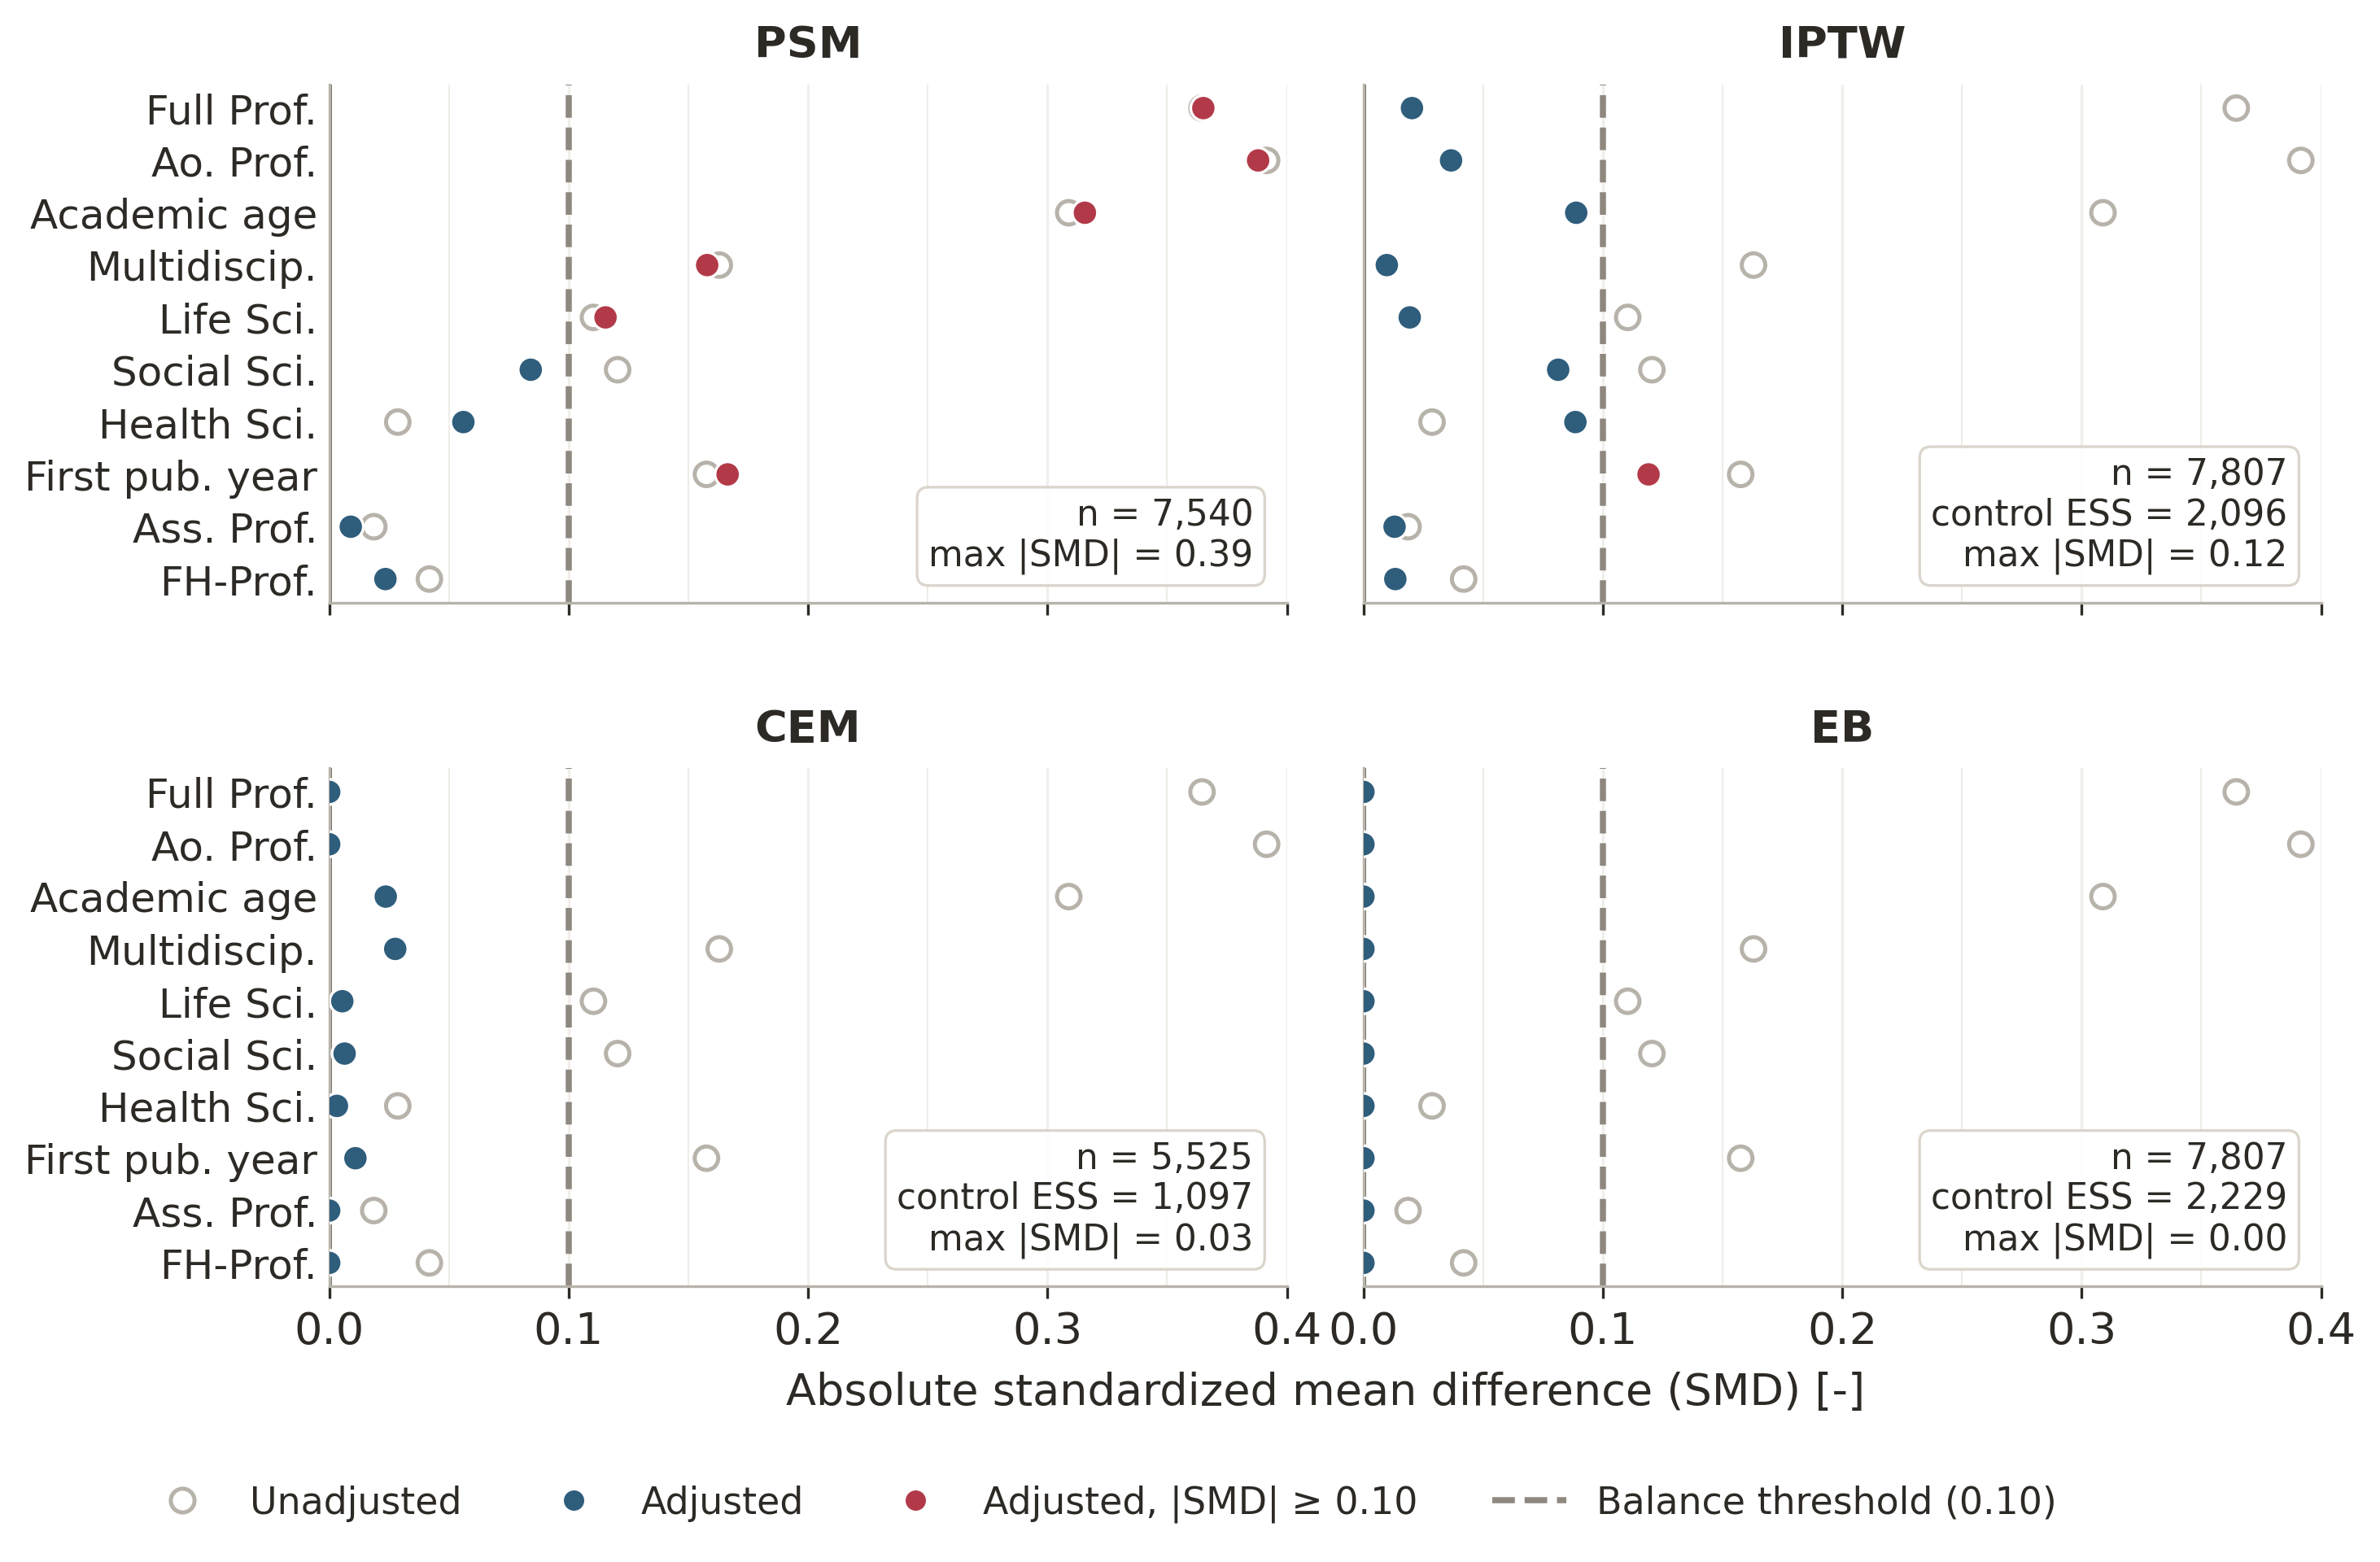

In [6]:
balance_plot_path = config.outputs.plots_dir / COVARIATE_BALANCE_FIGURE_FILENAME
if not balance_plot_path.is_file():
    raise FileNotFoundError(f'Covariate-balance plot was not produced: {balance_plot_path}')
display(Image(filename=str(balance_plot_path)))

PSM had the most residual imbalance: six covariates remained above 0.10, including Ao. Prof. (SMD 0.39), Full Prof. (0.37), and academic age (0.32). With IPTW, only first publication year remained above threshold (0.12). CEM (maximum SMD 0.03) and EB (below 0.01) balanced every covariate. Before adjustment, Ao. Prof. and Full Prof. both exceeded 0.30.